# FMA metadata exploration

This notebook reads the verified FMA metadata and inventory. Each figure and table uses unique track IDs. On WCSS, execute it in a Slurm CPU job with nbconvert and open the resulting notebook in OOD JupyterLab with the **Music Atlas** kernel.

By default the catalogue includes inventory tracks marked present. Set `USE_AUDIT = True` below, or pass `ATLAS_FMA_USE_AUDIT=1` to the batch run, to retain the track IDs marked valid in `manifests/tracks.parquet`. Durations come from the published metadata in both runs.

In [7]:
import os
from ast import literal_eval

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.ticker import PercentFormatter

from music_atlas.settings import paths

USE_AUDIT = os.environ.get("ATLAS_FMA_USE_AUDIT") == "1"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f8fafc",
    "axes.labelcolor": "#24334a",
    "axes.edgecolor": "#d4deea",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "text.color": "#17253d",
    "xtick.color": "#3b4d65",
    "ytick.color": "#3b4d65",
    "grid.color": "#dbe4ed",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})

data = paths()["data"]
metadata = data / "fma/fma_metadata"
inventory = pd.read_csv(
    data / "manifests/fma_full_inventory.csv",
    usecols=["track_id", "status", "sha1"],
    index_col="track_id",
)
assert inventory.index.is_unique and not inventory.index.hasnans
ids = inventory.index[inventory["status"].eq("present")]
if USE_AUDIT:
    audit = pd.read_parquet(
        data / "manifests/tracks.parquet", columns=["track_id", "valid", "duplicate_group"]
    ).set_index("track_id")
    assert audit.index.is_unique and not audit.index.hasnans
    assert pd.api.types.is_bool_dtype(audit["valid"]) and audit["valid"].notna().all()
    print(f"{len(ids.difference(audit.index)):,} present tracks lack an audit row.")
    ids = ids.intersection(audit.index[audit["valid"]])

assert len(ids), "The selected catalogue is empty."
fields = {
    ("artist", "id"): "artist_id",
    ("album", "id"): "album_id",
    ("set", "split"): "split",
    ("track", "duration"): "duration",
    ("track", "genres"): "genres",
    ("track", "genres_all"): "genres_all",
}
tracks = pd.read_csv(metadata / "tracks.csv", index_col=0, header=[0, 1], low_memory=False)
assert tracks.index.is_unique
missing_rows = len(ids.difference(tracks.index))
tracks = tracks[list(fields)].reindex(ids)
tracks.columns = list(fields.values())
for field in ["artist_id", "album_id"]:
    tracks[field] = tracks[field].where(tracks[field] > 0)

catalogue = "audited" if USE_AUDIT else "pre-audit"
print(f"{len(tracks):,} tracks ({catalogue}), {missing_rows:,} without a metadata row.")

106,574 tracks (pre-audit), 0 without a metadata row.


## Genres and their hierarchy

**Direct** counts tracks explicitly tagged with that genre in FMA's **genres** column. **With descendants** counts tracks tagged with the genre or any of its subgenres, using **genres_all**. For example, a track tagged only Punk counts directly under Punk and also toward Rock's total with descendants. Each track counts once per genre even if several tags lead to the same ancestor.

Expand the table to see every FMA genre, its immediate parent, its top-level branch and both counts. A blank parent identifies a top-level genre. The two counts use the same selected catalogue. [FMA metadata preparation](https://github.com/mdeff/fma/blob/master/creation.ipynb)

In [8]:
genres = pd.read_csv(metadata / "genres.csv", index_col="genre_id")
labels = tracks[["genres", "genres_all"]].fillna("[]").map(literal_eval)
direct = labels["genres"].explode().dropna().reset_index(name="genre_id").drop_duplicates()
inclusive = labels["genres_all"].explode().dropna().reset_index(name="genre_id").drop_duplicates()
assert genres.index.is_unique
assert (
    direct["genre_id"].isin(genres.index).all() and inclusive["genre_id"].isin(genres.index).all()
)
assert pd.MultiIndex.from_frame(direct).isin(pd.MultiIndex.from_frame(inclusive)).all()

genres["Direct"] = direct["genre_id"].value_counts().reindex(genres.index, fill_value=0)
genres["With descendants"] = (
    inclusive["genre_id"].value_counts().reindex(genres.index, fill_value=0)
)

listing = genres.assign(
    Parent=genres["parent"].map(genres["title"]).fillna(""),
    Branch=genres["top_level"].map(genres["title"]),
).sort_values(["Branch", "parent", "title"])
listing = listing[["title", "Parent", "Branch", "Direct", "With descendants"]]
display(
    HTML(
        f"<details><summary>Full FMA genre list ({len(listing)})</summary>"
        f"{listing.rename(columns={'title': 'Genre'}).to_html(index=True)}</details>"
    )
)

roots = genres[genres["parent"].eq(0)]
children = genres[genres["parent"].ne(0)].nlargest(10, "With descendants")

def plot_genre_counts(rows, title):
    fig, ax = plt.subplots(figsize=(8, 1.5 + 0.31 * len(rows)), layout="constrained")
    rows.sort_values("With descendants").set_index("title")[
        ["Direct", "With descendants"]
    ].plot.barh(ax=ax, color=["#5352a3", "#2a9d8f"], width=0.76, title=title)
    ax.set(xlabel="Unique tracks", ylabel="")
    ax.xaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="x")
    ax.legend(loc="lower right", facecolor="white")
    plt.show()

,Genre,Parent,Branch,Direct,With descendants
genre_id,,,,,
3,Blues,,Blues,1695,1752
567,Gospel,Blues,Blues,66,66
5,Classical,,Classical,2101,4106
187,20th Century Classical,Classical,Classical,292,292
442,Chamber Music,Classical,Classical,170,170
443,Choral Music,Classical,Classical,216,216
322,Composed Music,Classical,Classical,630,630
659,Contemporary Classical,Classical,Classical,1239,1239
441,Opera,Classical,Classical,161,161


### Top-level genres

Each pair of bars compares explicit tags with the total that includes subgenres. A large gap shows that much of a branch's support comes from more specific tags. Tracks can contribute to more than one branch.

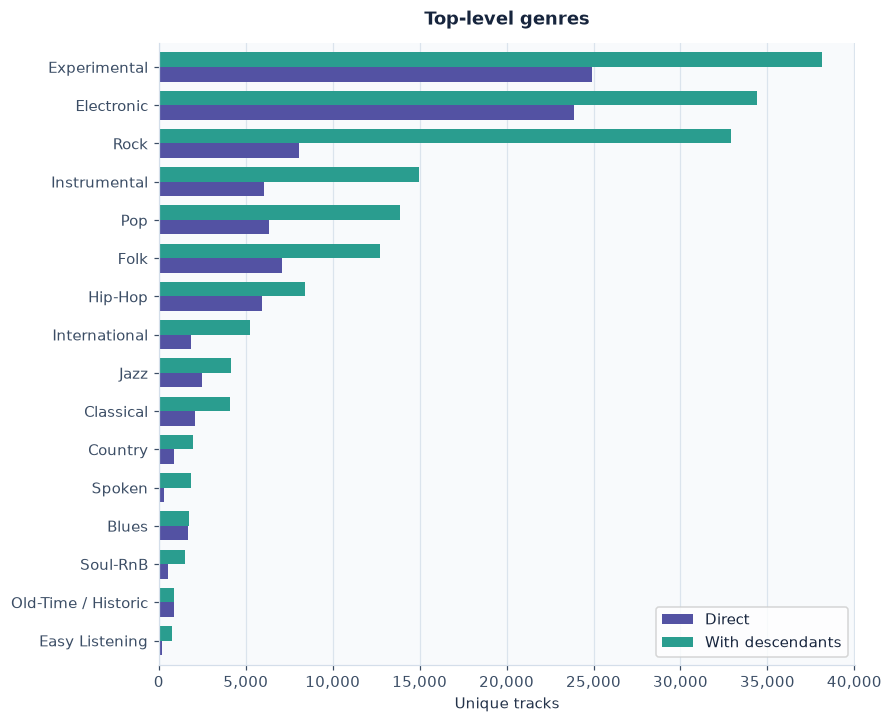

In [9]:
plot_genre_counts(roots, "Top-level genres")

### Most frequent subgenres

These are the ten genres below the top level with the largest inclusive counts. A subgenre can have descendants of its own. The same pair of bars shows how much support comes from more specific tags.

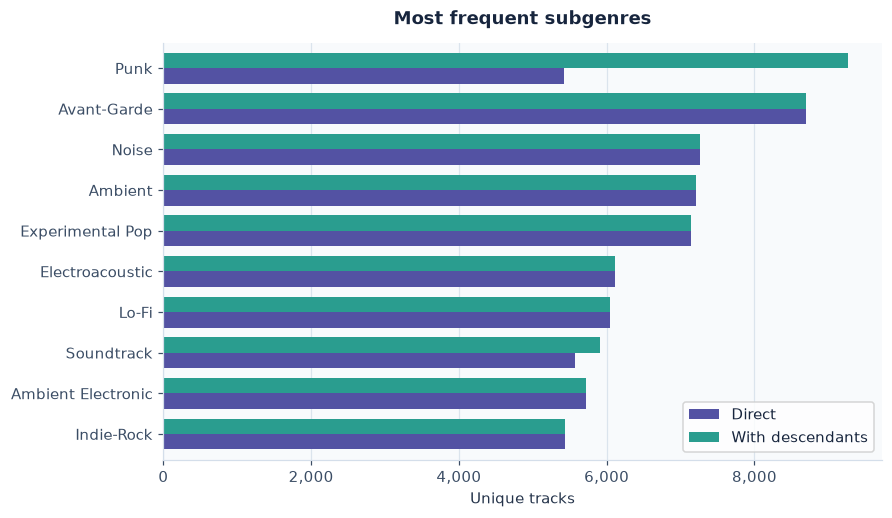

In [10]:
plot_genre_counts(children, "Most frequent subgenres")

___
## Which direct labels appear together?

Rows and columns show the ten most frequent **direct** labels. Each cell shows the percentage of tracks with **both** labels among the tracks with **at least one** of them. For example, 20 shared tracks out of 100 in the union give 20%. This measure is called Jaccard overlap.

Darker colours show greater overlap. The diagonal is blank because each label would overlap perfectly with itself. Counting explicit tags keeps parent–child relationships from automatically creating overlap. The heatmap measures shared annotations, and FMA's tags may be incomplete.

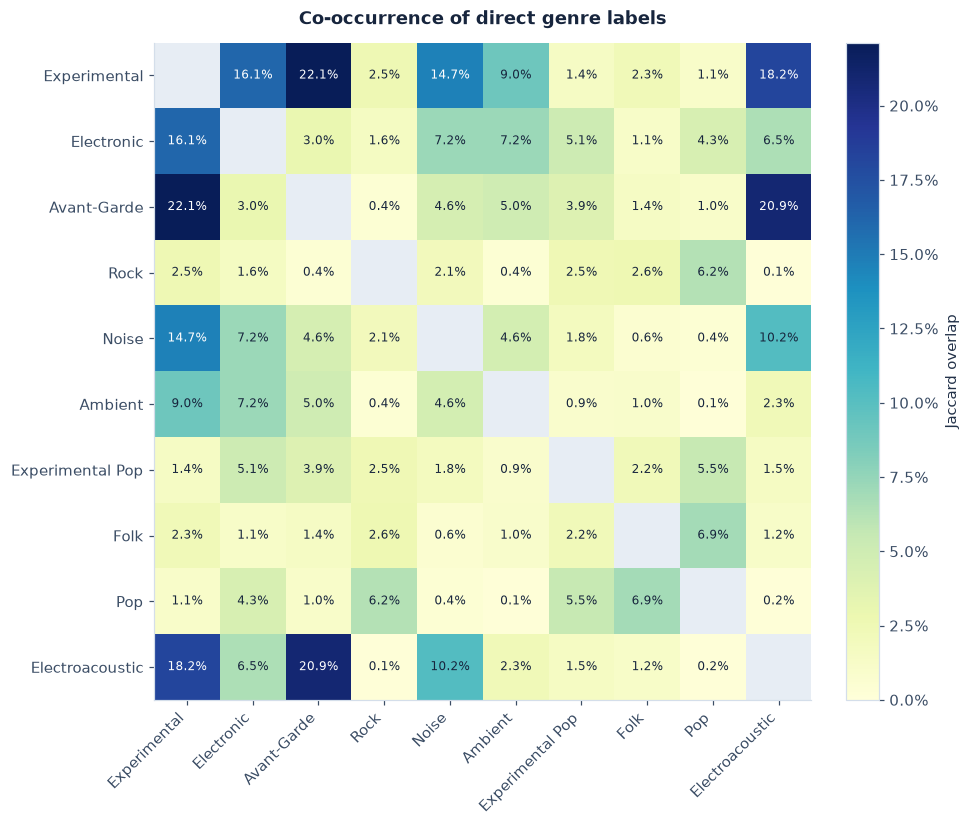

In [11]:
common = genres[genres["Direct"].gt(0)].nlargest(10, "Direct").index
if len(common) >= 2:
    selected = direct[direct["genre_id"].isin(common)]
    flags = pd.crosstab(selected["track_id"], selected["genre_id"]).reindex(columns=common)
    flags = flags.to_numpy(dtype=np.int64)
    shared = flags.T @ flags
    totals = shared.diagonal()
    similarity = shared / (totals + totals[:, None] - shared)
    np.fill_diagonal(similarity, np.nan)

    fig, ax = plt.subplots(figsize=(8.8, 7.4), layout="constrained")
    cmap = plt.get_cmap("YlGnBu").with_extremes(bad="#e7edf4")
    vmax = np.nanmax(similarity) or 1
    heatmap = ax.imshow(similarity, cmap=cmap, vmin=0, vmax=vmax)
    for (row, col), value in np.ndenumerate(similarity):
        if np.isfinite(value):
            ax.text(
                col, row, f"{value:.1%}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.6 * vmax else "#17253d",
            )
    ax.set_xticks(range(len(common)), genres.loc[common, "title"], rotation=45, ha="right")
    ax.set_yticks(range(len(common)), genres.loc[common, "title"])
    ax.set_title("Co-occurrence of direct genre labels")
    fig.colorbar(heatmap, ax=ax, label="Jaccard overlap", format=PercentFormatter(1))
    plt.show()
else:
    print("Co-occurrence requires at least two observed genres.")

___
## Artist concentration

Artists are ranked from most to least tracks. At rank 10, the curve gives the share of the entire selected catalogue belonging to the ten largest artists. A steep rise signals concentration and can make an artist-heavy label look well supported even when it has few independent performers. The rank axis is logarithmic. Tracks with unknown artist IDs contribute to the denominator only.

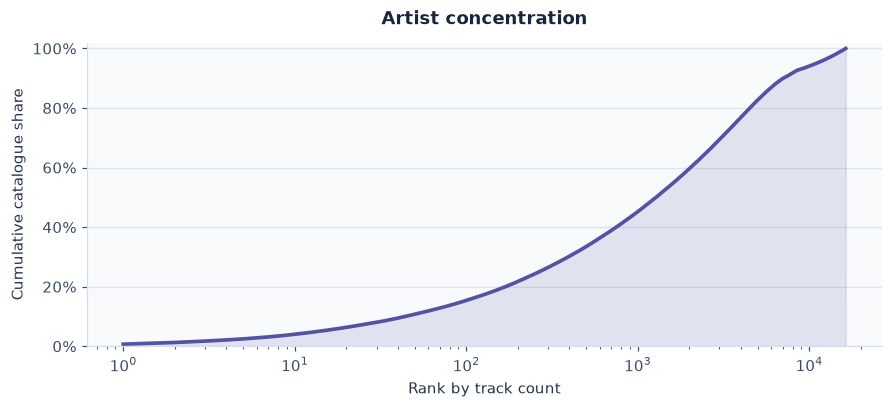

In [12]:
def plot_concentration(field, title, colour):
    counts = tracks[field].value_counts()
    ranks = np.arange(1, len(counts) + 1)
    shares = counts.cumsum().to_numpy() / len(tracks)
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    ax.plot(ranks, shares, color=colour, linewidth=2.4)
    ax.fill_between(ranks, shares, color=colour, alpha=0.14)
    ax.set(
        xscale="log", xlabel="Rank by track count", ylim=(0, 1.02),
        ylabel="Cumulative catalogue share", title=title,
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y")
    plt.show()


plot_concentration("artist_id", "Artist concentration", "#5352a3")

___
## Album concentration

The same curve ranks albums. At rank 10, it shows how much of the full catalogue comes from the ten largest albums. A steep rise indicates that a few releases contain many tracks. Tracks with unknown album IDs contribute to the denominator only, so the curve can end below 100%.

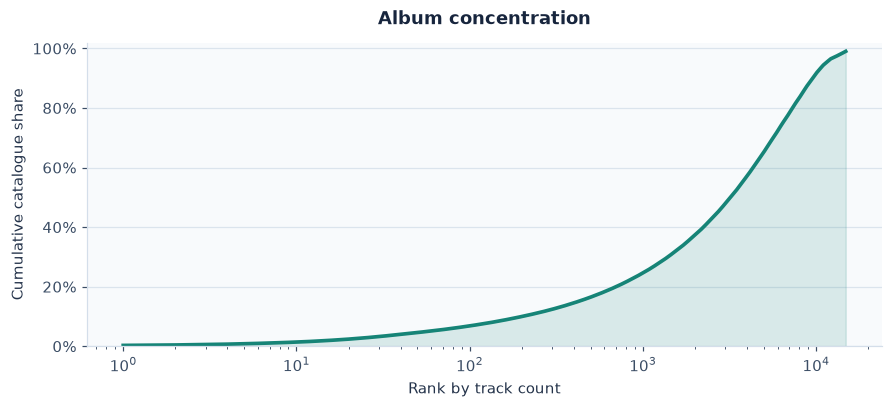

In [13]:
plot_concentration("album_id", "Album concentration", "#168477")

___
## Track durations

The histogram uses FMA's published duration in seconds. The horizontal axis is logarithmic so short and long recordings are readable on the same chart. The dashed line marks the median of positive, finite values. The coverage chart below counts missing and invalid durations.

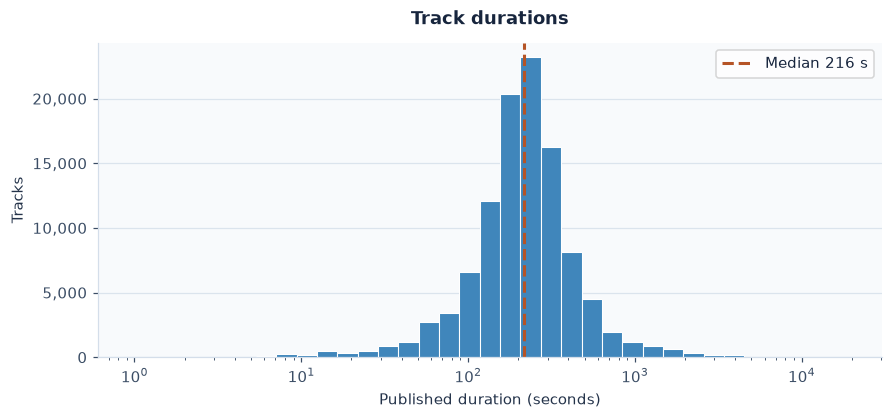

In [14]:
durations = tracks["duration"].dropna()
durations = durations[durations.gt(0) & np.isfinite(durations)]

if durations.empty:
    print("No positive, finite durations are available.")
else:
    fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
    bins = np.geomspace(durations.min() * 0.99, durations.max() * 1.01, 36)
    ax.hist(durations, bins=bins, color="#4086bb", edgecolor="white", linewidth=0.7)
    ax.axvline(
        durations.median(), color="#b55426", linestyle="--", linewidth=2,
        label=f"Median {durations.median():g} s",
    )
    ax.set(
        xscale="log", xlabel="Published duration (seconds)", ylabel="Tracks",
        title="Track durations",
    )
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="y")
    ax.legend(facecolor="white")
    plt.show()

___
## Annotation and metadata coverage

Bars show the percentage of **all selected tracks**, with counts printed at the end. The first three bars describe how many direct tags a track has. The fourth counts tracks spanning more than one top-level branch. Missing fields can overlap with each other and with the annotation categories. Treat absent genre tags as unknown.

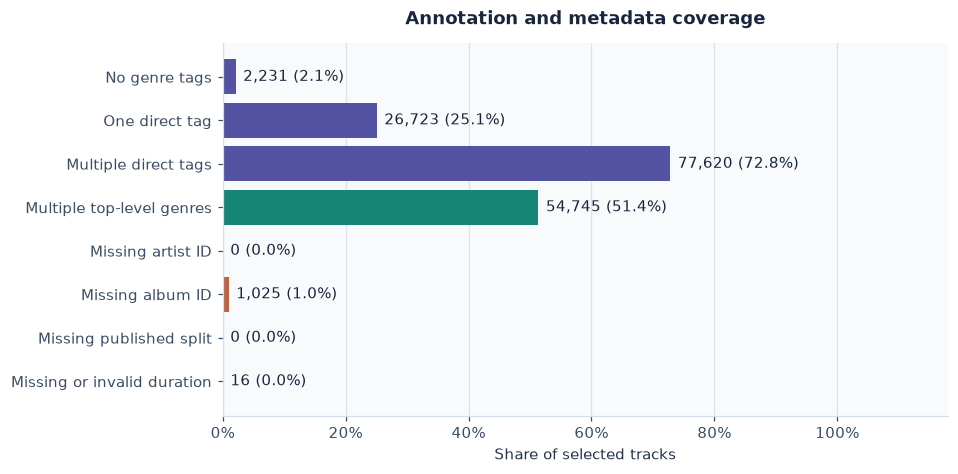

In [15]:
root_tags = inclusive[inclusive["genre_id"].isin(roots.index)]
roots_per_track = root_tags.groupby("track_id").size().reindex(ids, fill_value=0)
labels_per_track = direct.groupby("track_id").size().reindex(ids, fill_value=0)
coverage = pd.Series(
    {
        "No genre tags": labels_per_track.eq(0).sum(),
        "One direct tag": labels_per_track.eq(1).sum(),
        "Multiple direct tags": labels_per_track.gt(1).sum(),
        "Multiple top-level genres": roots_per_track.gt(1).sum(),
        "Missing artist ID": tracks["artist_id"].isna().sum(),
        "Missing album ID": tracks["album_id"].isna().sum(),
        "Missing published split": tracks["split"].isna().sum(),
        "Missing or invalid duration": len(tracks) - len(durations),
    }
)

shares = coverage / len(tracks)
fig, ax = plt.subplots(figsize=(8.6, 4.2), layout="constrained")
bars = ax.barh(
    coverage.index, shares, color=["#5352a3"] * 3 + ["#168477"] + ["#bd6447"] * 4
)
ax.bar_label(
    bars,
    labels=[f"{count:,} ({share:.1%})" for count, share in zip(coverage, shares, strict=True)],
    padding=5,
)
ax.set(xlabel="Share of selected tracks", xlim=(0, 1.18), title="Annotation and metadata coverage")
ax.set_xticks(np.linspace(0, 1, 6))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.grid(axis="x")
plt.show()

___
## Rare labels and split leakage

The first table lists observed direct labels with the fewest known artists, using track count to break ties. The second shows labels with at least 20 tracks where one artist supplies the largest share. Both flag labels that may be hard to score across independent performers.

The final table counts artist IDs, album IDs and identical audio hashes seen in multiple published splits. In audited mode it also counts duplicate groups supplied by the audit. If a group spans splits, keeping its tracks together in the new split reduces leakage.

In [16]:
tagged = direct.join(tracks["artist_id"], on="track_id")
artist_counts = tagged.groupby(["genre_id", "artist_id"]).size().groupby(level=0)
support = (
    genres[["title", "Direct"]]
    .query("Direct > 0")
    .assign(
        Artists=artist_counts.size().reindex(genres.index, fill_value=0),
        Top_artist_pct=(100 * artist_counts.max() / genres["Direct"]).round(1),
    )
)
rare = support.nsmallest(5, ["Artists", "Direct"])
concentrated = support.query("Direct >= 20").nlargest(3, "Top_artist_pct").dropna()
print("Observed genres with the fewest artists")
display(rare)
print("Most concentrated genres with at least 20 direct tags")
display(concentrated)

split_groups = tracks[["artist_id", "album_id", "split"]].join(inventory["sha1"])
if USE_AUDIT:
    split_groups = split_groups.join(audit["duplicate_group"])

group_fields = {
    "artist_id": "Artists",
    "album_id": "Albums",
    "sha1": "Exact audio groups (SHA-1)",
    "duplicate_group": "Audit duplicate groups",
}
split_overlap = pd.Series({
    label: split_groups.groupby(field)["split"].nunique().gt(1).sum()
    for field, label in group_fields.items()
    if field in split_groups
})
display(split_overlap.rename("Groups spanning published splits").to_frame())

Observed genres with the fewest artists


,title,Direct,Artists,Top_artist_pct
genre_id,,,,
377,Deep Funk,1,1,100.0
173,N. Indian Traditional,4,2,75.0
374,Banter,9,2,55.6
493,Western Swing,4,3,50.0
808,Salsa,12,3,58.3


Most concentrated genres with at least 20 direct tags


,title,Direct,Artists,Top_artist_pct
genre_id,,,,
189,Talk Radio,26,5,84.6
65,Radio,166,8,83.1
176,Pacific,23,4,73.9


,Groups spanning published splits
Artists,0
Albums,670
Exact audio groups (SHA-1),11


___
## Candidate A — nine groups covering every branch

**Soul-RnB** is FMA's branch for soul and rhythm and blues (R&B). It includes tags such as Funk and Deep Funk. **Easy Listening** includes tags such as Lounge. The proposed names put these branches alongside Jazz and Blues, and Instrumental, respectively.

The table maps all 16 original branches to broader labels. Track counts are deduplicated within each proposed group. A track can still have several groups. Spoken Word stays visible for catalogue exploration and can be excluded from a music-only classifier.

**Tracks** counts unique tracks per group. **Artists** counts known artist IDs, and **Top artist (%)** is the share of the group's tracks from its most prolific artist. Compare track and artist counts to spot groups whose support depends on relatively few performers.

In [17]:
groups = {
    "Rock & Pop": (12, 10),
    "Electronic": (15,),
    "Hip-Hop": (21,),
    "Jazz, Blues & Soul": (4, 3, 14),
    "Folk, Country & Regional": (17, 9, 2, 8),
    "Classical": (5,),
    "Instrumental & Lounge": (1235, 13),
    "Experimental": (38,),
    "Spoken Word": (20,),
}
group_for_root = {root: group for group, root_ids in groups.items() for root in root_ids}
assert set(group_for_root) == set(roots.index)
assert len(group_for_root) == sum(map(len, groups.values()))

group_tags = root_tags.assign(Group=root_tags["genre_id"].map(group_for_root))
group_tags = group_tags.drop_duplicates(["track_id", "Group"]).join(
    tracks["artist_id"], on="track_id"
)
group_summary = group_tags.groupby("Group").agg(
    Tracks=("track_id", "size"), Artists=("artist_id", "nunique")
)
group_summary = group_summary.reindex(groups, fill_value=0)
leading_artists = group_tags.groupby(["Group", "artist_id"]).size().groupby(level=0).max()
group_summary["Top artist (%)"] = (100 * leading_artists / group_summary["Tracks"]).round(1)
group_summary["FMA branches"] = [
    " + ".join(genres.loc[list(group), "title"]) for group in groups.values()
]
display(group_summary[["FMA branches", "Tracks", "Artists", "Top artist (%)"]])

groups_per_track = group_tags.groupby("track_id").size().reindex(ids, fill_value=0)
assert groups_per_track.le(roots_per_track).all()
assert groups_per_track.gt(0).equals(roots_per_track.gt(0))
print(
    f"{roots_per_track.gt(1).sum():,} tracks span original branches, and "
    f"{groups_per_track.gt(1).sum():,} span proposed groups."
)

,FMA branches,Tracks,Artists,Top artist (%)
Group,,,,
Rock & Pop,Rock + Pop,41190,5734,0.8
Electronic,Electronic,34413,6135,1.6
Hip-Hop,Hip-Hop,8389,999,2.5
"Jazz, Blues & Soul",Jazz + Blues + Soul-RnB,7016,1087,5.0
"Folk, Country & Regional",Folk + Country + International + Old-Time / Hi...,18534,2897,1.9
Classical,Classical,4106,451,13.4
Instrumental & Lounge,Instrumental + Easy Listening,15521,2389,4.3
Experimental,Experimental,38154,6949,1.9
Spoken Word,Spoken,1876,379,7.4


54,745 tracks span original branches, and 50,442 span proposed groups.


___
## Candidate B — eight familiar genre labels

The 2023 IFPI survey asked 43,000 people in 26 countries about the music they listen to. Its global favourites, in rank order, were Pop, Rock, Hip-Hop/Rap, Dance/Electronic, Latin, R&B, Classical/Opera, Country, Soundtracks and Reggae. This is a listener survey. The support table below measures FMA coverage. [IFPI Engaging with Music 2023](https://www.ifpi.org/wp-content/uploads/2023/12/IFPI-Engaging-With-Music-2023_full-report.pdf)

The proposal uses the survey's top four and Classical, and adds three familiar FMA categories: Punk, Jazz and Blues. Each label takes an FMA genre and its descendants. Punk sits under Rock in FMA. A track with a Punk tag or one of its descendants receives Punk in place of Rock, so that pair is mutually exclusive. Other combinations remain possible.

The other branches stay available in Candidate A. Tracks with no matching label are counted as unassigned here. The table shows track counts and known artists, and the bars compare track counts across the eight classes.

In [18]:
popular_genres = {
    "Pop": 10,
    "Rock": 12,
    "Punk": 25,
    "Hip-Hop": 21,
    "Electronic & Dance": 15,
    "Classical": 5,
    "Jazz": 4,
    "Blues": 3,
}
assert set(popular_genres.values()).issubset(genres.index)
rock = popular_genres["Rock"]
punk = popular_genres["Punk"]
assert genres.at[punk, "top_level"] == rock

label_for_genre = {genre_id: label for label, genre_id in popular_genres.items()}
popular_tags = inclusive[inclusive["genre_id"].isin(label_for_genre)].copy()
punk_ids = popular_tags.loc[popular_tags["genre_id"].eq(punk), "track_id"]
inherited_rock = popular_tags["genre_id"].eq(rock) & popular_tags["track_id"].isin(punk_ids)
popular_tags = popular_tags.loc[~inherited_rock].assign(
    Group=lambda tags: tags["genre_id"].map(label_for_genre)
).join(tracks["artist_id"], on="track_id")

popular_summary = popular_tags.groupby("Group").agg(
    Tracks=("track_id", "size"), Artists=("artist_id", "nunique")
).reindex(popular_genres, fill_value=0)
assert popular_summary.loc["Punk", "Tracks"] == len(punk_ids)
assert popular_summary.loc["Rock", "Tracks"] + len(punk_ids) == genres.at[rock, "With descendants"]
popular_summary["FMA genre"] = [
    genres.at[genre_id, "title"] for genre_id in popular_genres.values()
]
display(popular_summary[["FMA genre", "Tracks", "Artists"]])

popular_per_track = popular_tags.groupby("track_id").size().reindex(ids, fill_value=0)
popular_covered = popular_per_track.gt(0).sum()
popular_unassigned = len(tracks) - popular_covered
print(
    f"{popular_covered:,} tracks assigned ({popular_covered / len(tracks):.1%} of the catalogue), "
    f"{popular_unassigned:,} unassigned, and "
    f"{popular_per_track.gt(1).sum():,} with multiple labels."
)

,FMA genre,Tracks,Artists
Group,,,
Pop,Pop,13845,2036
Rock,Rock,23662,3478
Punk,Punk,9261,1288
Hip-Hop,Hip-Hop,8389,999
Electronic & Dance,Electronic,34413,6135
Classical,Classical,4106,451
Jazz,Jazz,4126,711
Blues,Blues,1752,169


79,214 tracks assigned (74.3% of the catalogue), 27,360 unassigned, and 18,709 with multiple labels.


### Class balance in Candidate B

Each bar shows the unique tracks assigned to one of the eight labels. Use the artist counts in the table above alongside these bars when deciding whether a class is large enough for evaluation. Since some tracks have more than one label, adding the bars can exceed the number of assigned tracks.

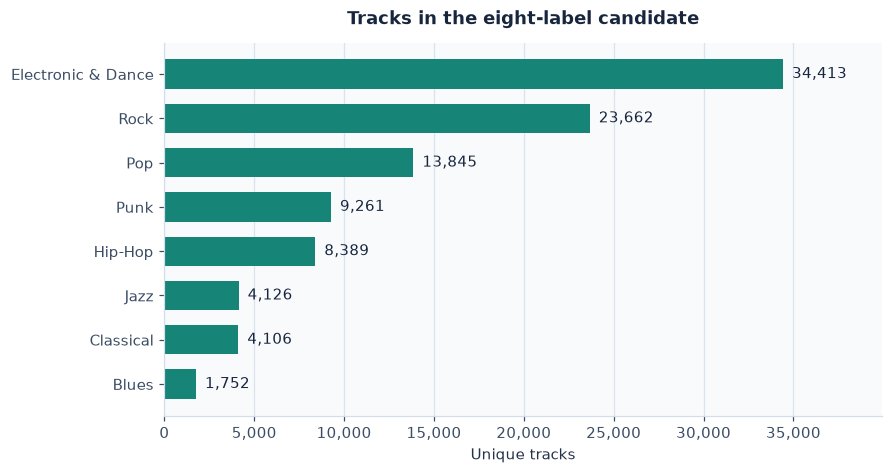

In [19]:
class_counts = popular_summary["Tracks"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
bars = ax.barh(
    class_counts.index, class_counts, color="#168477",
    height=0.66,
)
ax.bar_label(bars, labels=[f"{count:,}" for count in class_counts], padding=6)
ax.set(
    title="Tracks in the eight-label candidate", xlabel="Unique tracks",
    xlim=(0, max(class_counts.max(), 1) * 1.16),
)
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="x")
plt.show()

___
## Interpretation

The figures describe the current catalogue. Use the support and leakage counts below to compare label sets and to design the artist-disjoint split after the audio audit.

In [20]:
largest = roots.nlargest(1, "With descendants").iloc[0]
rare_count = support["Artists"].lt(3).sum()
missing_genre = coverage["No genre tags"]
missing_artist = coverage["Missing artist ID"]
missing_album = coverage["Missing album ID"]
invalid_duration = coverage["Missing or invalid duration"]
short_tracks = durations.lt(10).sum()

findings = [
    f"**Label support.** {largest['title']} has {largest['Direct']:,} direct tags and "
    f"{largest['With descendants']:,} tracks including descendants. "
    f"{rare_count:,} observed direct genres have fewer than three known artists. "
    f"Candidate A covers {groups_per_track.gt(0).sum():,} tracks. Candidate B covers "
    f"{popular_covered:,}, with {popular_per_track.gt(1).sum():,} carrying multiple labels. "
    "Before scoring a class, verify track and independent group support in each proposed split.",
    f"**Coverage.** {missing_genre:,} tracks lack genre tags, "
    f"{missing_artist:,} lack an artist ID, and {missing_album:,} lack an album ID. "
    f"{invalid_duration:,} durations are missing or invalid, "
    f"and {short_tracks:,} valid published durations are under 10 seconds. "
    "Use annotated tracks for supervised scoring, treat missing tags as unknown and check short "
    "recordings against the audio audit before choosing windows.",
    f"**Split design.** The published partitions share {split_overlap['Artists']:,} artist IDs, "
    f"{split_overlap['Albums']:,} album IDs and "
    f"{split_overlap['Exact audio groups (SHA-1)']:,} exact audio groups. "
    "Keep artists, confirmed duplicate groups and fragments of a recording in one partition. "
    "Check shared albums and review classes dominated by one artist before freezing the split.",
]
if not concentrated.empty:
    top = concentrated.iloc[0]
    findings[0] += f" One artist accounts for {top['Top_artist_pct']:g}% of {top['title']} tags."
if USE_AUDIT:
    findings[2] += (
        f" {split_overlap['Audit duplicate groups']:,} audit duplicate groups span "
        "the published partitions among valid tracks."
    )
display(Markdown("\n\n".join(findings)))

**Label support.** Experimental has 24,912 direct tags and 38,154 tracks including descendants. 3 observed direct genres have fewer than three known artists. Candidate A covers 104,343 tracks. Candidate B covers 79,214, with 18,709 carrying multiple labels. Before scoring a class, verify track and independent group support in each proposed split. One artist accounts for 84.6% of Talk Radio tags.

**Coverage.** 2,231 tracks lack genre tags, 0 lack an artist ID, and 1,025 lack an album ID. 16 durations are missing or invalid, and 512 valid published durations are under 10 seconds. Use annotated tracks for supervised scoring, treat missing tags as unknown and check short recordings against the audio audit before choosing windows.

**Split design.** The published partitions share 0 artist IDs, 670 album IDs and 11 exact audio groups. Keep artists, confirmed duplicate groups and fragments of a recording in one partition. Check shared albums and review classes dominated by one artist before freezing the split.